# Lab Assignment 8: Seq2Seq with Attention

**Student:** Muhammad Obaidullah (abdulsalam.m@northeastern.edu)  
**Course:** Applied NLP  
**Submission:** Upload `Lab_8.ipynb` to Canvas with all cells run and outputs visible.

---

## Overview

The encoder-decoder architecture compresses an entire source sentence into a single fixed-size vector before generating the translation. This works acceptably for short sentences but fails systematically as sentences grow longer — the single vector becomes a bottleneck. The attention mechanism resolves this by allowing the decoder to consult the full sequence of encoder states at every generation step, learning which source positions are most relevant for each output word.

In this lab you will implement both architectures on English→German translation, directly measure the bottleneck failure mode, implement BLEU scoring from scratch, and interpret the linguistic relationships encoded in learned attention weight matrices.

---

## Learning Objectives

1. Compare encoder-decoder models with and without attention, diagnosing the bottleneck failure mode that attention resolves
2. Implement a seq2seq model with Bahdanau-style attention
3. Analyze learned attention weight distributions and interpret what linguistic relationships the model has captured
4. Evaluate neural machine translation output using BLEU score, critiquing what BLEU measures and where it misleads

---

## Grading

| Component | Points | Method |
|---|---|---|
| Part 1 — Seq2seq without attention (bottleneck baseline) | 22 | Autograded (16) + Manual (6) |
| Part 2 — Bahdanau attention implementation | 28 | Autograded (22) + Manual (6) |
| Part 3 — Attention weight analysis | 20 | Autograded (8) + Manual (12) |
| Part 4 — BLEU evaluation | 16 | Autograded (10) + Manual (6) |
| Code quality | 14 | Manual |
| **Total** | **100** | |

### Manual grading rubric

**Reflections (6 pts each, Parts 1–2 and 4; 12 pts Part 3):**  
Full credit requires a specific, evidence-grounded claim with a concrete linguistic or architectural mechanism, using precise NLP terminology.

**Code quality (14 pts):**

| Criterion | Points |
|---|---|
| Docstrings and inline comments | 4 |
| Function design | 4 |
| Defensive coding | 3 |
| Code clarity and naming | 2 |
| Avoiding redundancy | 1 |

---

## Setup

**Runtime requirement:** Use a GPU for reasonable training times.  
In Google Colab: *Runtime → Change runtime type → T4 GPU.*

In [1]:
# Setup — run this cell first every session.

import subprocess, sys

def install_if_missing(package, pip_name=None):
    """Install a package if it cannot be imported.

    Args:
        package  (str): The importable module name to check.
        pip_name (str): pip install name if different from package.
    """
    try:
        __import__(package)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip",
                               "install", pip_name or package, "-q"])

install_if_missing("torch")
install_if_missing("sacrebleu")
install_if_missing("numpy")
install_if_missing("matplotlib")

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import (pad_sequence, pack_padded_sequence,
                                pad_packed_sequence)
import numpy as np
import matplotlib.pyplot as plt
import random, math, re, os, urllib.request, zipfile, io, time
import bisect
from collections import Counter, defaultdict
import warnings
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
PAD, SOS, EOS = 0, 1, 2

print(f"Device: {DEVICE}")
if DEVICE.type == 'cpu':
    print("No GPU detected — training will be slow. "
          "Colab: Runtime → Change runtime type → T4 GPU.")

Device: cpu
No GPU detected — training will be slow. Colab: Runtime → Change runtime type → T4 GPU.


---

## Data loading and preprocessing

We use the **Multi30k English→German** dataset — 30,000 image caption pairs, average ~12 words per sentence. We work at the **word level** so that attention heatmaps show interpretable word-to-word alignments.

Both sides are lowercased, punctuation is spaced, and pairs are filtered to a maximum of 20 words on either side to keep training manageable on a T4 GPU.

In [2]:
# [DO NOT MODIFY] — data download and preprocessing

TRAIN_EN_URL = "https://raw.githubusercontent.com/multi30k/dataset/master/data/task1/raw/train.en.gz"
TRAIN_DE_URL = "https://raw.githubusercontent.com/multi30k/dataset/master/data/task1/raw/train.de.gz"
VAL_EN_URL   = "https://raw.githubusercontent.com/multi30k/dataset/master/data/task1/raw/val.en.gz"
VAL_DE_URL   = "https://raw.githubusercontent.com/multi30k/dataset/master/data/task1/raw/val.de.gz"


def download_gz(url, dest):
    """Download a .gz file and write the decompressed content to dest."""
    import gzip
    if os.path.exists(dest):
        return
    print(f"Downloading {url.split('/')[-1]} ...")
    with urllib.request.urlopen(url) as r:
        with gzip.open(r) as gz, open(dest, 'w', encoding='utf-8') as f:
            f.write(gz.read().decode('utf-8'))


def normalize(s):
    """Lowercase, space punctuation, collapse whitespace."""
    s = s.lower().strip()
    s = re.sub(r'([.!?,;:])', r' \1', s)
    s = re.sub(r'\s+', ' ', s)
    return s.strip()


def load_pairs(en_path, de_path, max_len=20):
    """Load and filter (English, German) sentence pairs.

    Args:
        en_path  (str): Path to English sentences (one per line).
        de_path  (str): Path to German sentences (one per line).
        max_len  (int): Maximum number of tokens per side after splitting.

    Returns:
        list[tuple[list[str], list[str]]]: (en_tokens, de_tokens) pairs.
    """
    pairs = []
    with open(en_path, encoding='utf-8') as ef, \
         open(de_path, encoding='utf-8') as df:
        for en_line, de_line in zip(ef, df):
            en_toks = normalize(en_line).split()
            de_toks = normalize(de_line).split()
            if 1 <= len(en_toks) <= max_len and 1 <= len(de_toks) <= max_len:
                pairs.append((en_toks, de_toks))
    return pairs


for url, dest in [(TRAIN_EN_URL, 'train.en'), (TRAIN_DE_URL, 'train.de'),
                  (VAL_EN_URL,   'val.en'),   (VAL_DE_URL,   'val.de')]:
    download_gz(url, dest)

train_pairs = load_pairs('train.en', 'train.de', max_len=20)
val_pairs   = load_pairs('val.en',   'val.de',   max_len=20)

print(f"Train: {len(train_pairs):,} pairs")
print(f"Val:   {len(val_pairs):,} pairs")
print(f"\nSample: {train_pairs[0][0]} → {train_pairs[0][1]}")

Train: 27,145 pairs
Val:   951 pairs

Sample: ['two', 'young', ',', 'white', 'males', 'are', 'outside', 'near', 'many', 'bushes', '.'] → ['zwei', 'junge', 'weiße', 'männer', 'sind', 'im', 'freien', 'in', 'der', 'nähe', 'vieler', 'büsche', '.']


### Vocabulary

In [3]:
class Vocabulary:
    """Word-to-index mapping with PAD/SOS/EOS reserved tokens.

    Indices 0, 1, 2 are reserved for <PAD>, <SOS>, <EOS>.
    Only words appearing at least min_freq times are included.

    Args:
        min_freq (int): Minimum token frequency to include.
    """

    # Only three indices are reserved, so an unknown word is encoded as
    # index 1 and shares the <SOS> embedding (see encode).
    UNK = SOS

    def __init__(self, min_freq=2):
        self.w2i  = {'<PAD>': PAD, '<SOS>': SOS, '<EOS>': EOS}
        self.i2w  = {PAD: '<PAD>', SOS: '<SOS>', EOS: '<EOS>'}
        self.freq = {}
        self.min_freq = min_freq
        self.size = 3

    def build(self, token_lists):
        """Build vocabulary from a list of token sequences.

        Counts all tokens, then adds those meeting min_freq to the mapping.

        Args:
            token_lists (list[list[str]]): Tokenized sentences.
        """
        if isinstance(self.min_freq, bool) or not isinstance(self.min_freq, int) \
                or self.min_freq < 1:
            raise ValueError(f"min_freq must be a positive int, got {self.min_freq!r}")
        counts = Counter()
        for tokens in token_lists:
            if isinstance(tokens, str):
                raise TypeError("token_lists must hold token lists, not strings")
            counts.update(tokens)
        for word, count in counts.items():
            self.freq[word] = self.freq.get(word, 0) + count

        # Most frequent words first, ties broken alphabetically, so the
        # indices are identical on every run.
        for word, count in sorted(self.freq.items(), key=lambda kv: (-kv[1], kv[0])):
            if count < self.min_freq:
                break
            if word not in self.w2i:            # skip words added by an earlier build
                self.w2i[word] = self.size
                self.i2w[self.size] = word
                self.size += 1

    def encode(self, tokens, add_sos=True, add_eos=True):
        """Convert tokens to indices, using <UNK>=1 for unknown words.

        Args:
            tokens   (list[str]): Token sequence.
            add_sos  (bool):      Prepend SOS token index.
            add_eos  (bool):      Append EOS token index.

        Returns:
            list[int]: Index sequence.
        """
        if isinstance(tokens, str):
            raise TypeError("encode expects a list of tokens; split the string first")
        indices = [self.w2i.get(tok, self.UNK) for tok in tokens]
        return ([SOS] if add_sos else []) + indices + ([EOS] if add_eos else [])

    def decode(self, indices):
        """Convert indices to a sentence string, skipping special tokens.

        Index 1 is skipped too, so an <UNK> prediction leaves no word.

        Args:
            indices (list[int]): Index sequence.

        Returns:
            str: Decoded sentence.
        """
        words = []
        for index in indices:
            index = int(index)                  # also accepts tensor elements
            if index in (PAD, SOS, EOS):
                continue
            if index not in self.i2w:
                raise ValueError(f"index {index} is outside the vocabulary "
                                 f"(size {self.size})")
            words.append(self.i2w[index])
        return ' '.join(words)


en_vocab = Vocabulary(min_freq=2)
de_vocab = Vocabulary(min_freq=2)

en_vocab.build([pair[0] for pair in train_pairs])
de_vocab.build([pair[1] for pair in train_pairs])

print(f"English vocab size: {en_vocab.size:,}")
print(f"German  vocab size: {de_vocab.size:,}")

# Sanity check
sample_en = train_pairs[0][0]
enc = en_vocab.encode(sample_en)
dec = en_vocab.decode(enc)
print(f"\nRoundtrip: {sample_en} → {enc[:6]}... → '{dec}'"  )

English vocab size: 5,603
German  vocab size: 7,163

Roundtrip: ['two', 'young', ',', 'white', 'males', 'are', 'outside', 'near', 'many', 'bushes', '.'] → [1, 13, 22, 19, 23, 782]... → 'two young , white males are outside near many bushes .'


In [4]:
class TranslationDataset(Dataset):
    """PyTorch Dataset for (source, target) sentence pairs.

    Each item is (source indices, target indices): the source is tokens + <EOS>,
    the target is <SOS> + tokens + <EOS>.

    Args:
        pairs     (list[tuple[list[str], list[str]]]): (src_tokens, tgt_tokens) pairs.
        src_vocab (Vocabulary): Source vocabulary.
        tgt_vocab (Vocabulary): Target vocabulary.
    """
    def __init__(self, pairs, src_vocab, tgt_vocab):
        # Sources are tokens + <EOS> with no <SOS>: Part 3's heatmap columns
        # are en.split() + ['<EOS>'], so training uses the same source format
        # as translation (see source_tensor in Part 1).
        self.data = [
            (torch.tensor(src_vocab.encode(en, add_sos=False), dtype=torch.long),
             torch.tensor(tgt_vocab.encode(de), dtype=torch.long))
            for en, de in pairs
        ]

    def __len__(self):
        """Number of sentence pairs."""
        return len(self.data)

    def __getitem__(self, i):
        """Return pair i as (src LongTensor, tgt LongTensor)."""
        return self.data[i]


def collate_fn(batch):
    """Pad variable-length sequence pairs to the longest in the batch.

    Args:
        batch (list[tuple[Tensor, Tensor]]): (source, target) pairs.

    Returns:
        tuple: (src_padded, tgt_padded) both shape (batch, max_len).
    """
    src_seqs, tgt_seqs = zip(*batch)
    src_padded = pad_sequence(src_seqs, batch_first=True, padding_value=PAD)
    tgt_padded = pad_sequence(tgt_seqs, batch_first=True, padding_value=PAD)
    return src_padded, tgt_padded


BATCH_SIZE = 128

train_dataset = TranslationDataset(train_pairs, en_vocab, de_vocab)
val_dataset   = TranslationDataset(val_pairs,   en_vocab, de_vocab)
train_loader  = DataLoader(train_dataset, BATCH_SIZE, shuffle=True,
                            collate_fn=collate_fn)
val_loader    = DataLoader(val_dataset,   BATCH_SIZE, shuffle=False,
                            collate_fn=collate_fn)

src_b, tgt_b = next(iter(train_loader))
print(f"Train batches: {len(train_loader)}   Val batches: {len(val_loader)}")
print(f"Batch — src: {src_b.shape}  tgt: {tgt_b.shape}")

Train batches: 213   Val batches: 8
Batch — src: torch.Size([128, 21])  tgt: torch.Size([128, 22])


---

## Part 1 — Seq2seq without Attention: Diagnosing the Bottleneck (22 points)

The baseline encoder-decoder compresses the entire source sentence into a single vector — the encoder's final hidden state. The decoder receives this vector once and uses it for the entire generation process. When the source sentence is short, this works adequately. When it is long, critical information from the beginning of the sentence has been overwritten by the time the encoder finishes processing the end.

### 1.1 — Encoder

In [5]:
def require_positive_ints(**named_values):
    """Raise ValueError unless every keyword argument is a positive int.

    Args:
        **named_values: name=value pairs to check, e.g. hidden_dim=256.
    """
    for name, value in named_values.items():
        if isinstance(value, bool) or not isinstance(value, int) or value <= 0:
            raise ValueError(f"{name} must be a positive int, got {value!r}")


def require_probability(name, value, allow_one=True):
    """Raise ValueError unless value lies in [0, 1] (or [0, 1) if not allow_one).

    Args:
        name      (str):   Argument name, used in the error message.
        value     (float): Value to check.
        allow_one (bool):  Whether 1.0 itself is allowed.
    """
    in_range = (isinstance(value, (int, float)) and not isinstance(value, bool)
                and 0.0 <= value and (value <= 1.0 if allow_one else value < 1.0))
    if not in_range:
        upper = '1]' if allow_one else '1)'
        raise ValueError(f"{name} must be in [0, {upper}, got {value!r}")


def source_lengths(src):
    """Number of non-PAD tokens in each row of a right-padded source batch.

    A row that is all padding counts as length 1, so packing (which rejects
    zero lengths) and the attention mask always keep one position.

    Args:
        src (LongTensor): Shape (batch, src_len).

    Returns:
        LongTensor: Shape (batch,), on the same device as src.
    """
    if src.dim() != 2:
        raise ValueError(f"src must have shape (batch, src_len), got {tuple(src.shape)}")
    return (src != PAD).sum(dim=1).clamp(min=1)


def length_mask(lengths, max_len):
    """Boolean mask that is True at real (unpadded) positions.

    Args:
        lengths (LongTensor): Real lengths, shape (batch,).
        max_len (int):        Padded sequence length.

    Returns:
        BoolTensor: Shape (batch, max_len).
    """
    positions = torch.arange(max_len, device=lengths.device)
    return positions.unsqueeze(0) < lengths.unsqueeze(1)


class BaselineEncoder(nn.Module):
    """Bidirectional LSTM encoder for the no-attention baseline.

    Reads the source sequence and returns:
      - all hidden states (for Part 2's attention to consume)
      - a single summary vector (concatenation of final forward/backward states,
        projected to hidden_dim) used as the decoder's initial state.

    Args:
        vocab_size (int):   Source vocabulary size.
        embed_dim  (int):   Embedding dimension.
        hidden_dim (int):   LSTM hidden units per direction.
        dropout    (float): Dropout on embeddings.
    """

    def __init__(self, vocab_size, embed_dim, hidden_dim, dropout=0.3):
        super().__init__()
        require_positive_ints(vocab_size=vocab_size, embed_dim=embed_dim,
                              hidden_dim=hidden_dim)
        require_probability('dropout', dropout, allow_one=False)
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True,
                            bidirectional=True)
        # Projects the concatenated final forward/backward states → hidden_dim.
        self.fc = nn.Linear(hidden_dim * 2, hidden_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, src):
        """Encode source sequence.

        Args:
            src (LongTensor): Shape (batch, src_len).

        Returns:
            tuple:
                encoder_outputs (Tensor): Shape (batch, src_len, hidden_dim*2).
                hidden          (Tensor): Shape (batch, hidden_dim) — initial
                                          decoder state (tanh of fc projection).

        Outputs at padded positions are zero.
        """
        lengths = source_lengths(src)
        embedded = self.dropout(self.embedding(src))        # (batch, src_len, embed_dim)
        # Packing stops each direction at the sentence's real end, so the
        # final states summarise the words rather than the padding.
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True,
                                      enforce_sorted=False)
        packed_out, (h_n, _) = self.lstm(packed)            # h_n: (2, batch, hidden_dim)
        encoder_outputs, _ = pad_packed_sequence(packed_out, batch_first=True,
                                                 total_length=src.size(1))
        # h_n[0] has read the sentence left to right, h_n[1] right to left.
        hidden = torch.tanh(self.fc(torch.cat([h_n[0], h_n[1]], dim=1)))
        return encoder_outputs, hidden

### 1.2 — Baseline decoder (no attention)

In [6]:
class BaselineDecoder(nn.Module):
    """LSTM decoder without attention.

    At every step, concatenates the embedding with the fixed context
    vector (the encoder's summary) and feeds it to the LSTM. The context
    never changes across decoder steps — this is the bottleneck.

    Args:
        vocab_size (int):   Target vocabulary size.
        embed_dim  (int):   Embedding dimension.
        hidden_dim (int):   LSTM hidden units.
        dropout    (float): Dropout on embeddings.
    """

    def __init__(self, vocab_size, embed_dim, hidden_dim, dropout=0.3):
        super().__init__()
        require_positive_ints(vocab_size=vocab_size, embed_dim=embed_dim,
                              hidden_dim=hidden_dim)
        require_probability('dropout', dropout, allow_one=False)
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD)
        # input = concat(embedding, fixed_context)
        self.lstm = nn.LSTM(embed_dim + hidden_dim, hidden_dim, batch_first=True)
        self.fc_out = nn.Linear(hidden_dim, vocab_size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, tgt_token, hidden, cell, context):
        """One decoding step.

        Args:
            tgt_token (LongTensor): Shape (batch,) — current input token.
            hidden    (Tensor):     Shape (batch, hidden_dim) — LSTM h.
            cell      (Tensor):     Shape (batch, hidden_dim) — LSTM c.
            context   (Tensor):     Shape (batch, hidden_dim) — fixed encoder
                                    summary, constant across all steps.

        Returns:
            tuple:
                logits   (Tensor): Shape (batch, vocab_size).
                hidden   (Tensor): Shape (batch, hidden_dim).
                cell     (Tensor): Shape (batch, hidden_dim).
        """
        if tgt_token.dim() != 1:
            raise ValueError(f"tgt_token must have shape (batch,), got {tuple(tgt_token.shape)}")
        embedded = self.dropout(self.embedding(tgt_token))           # (batch, embed_dim)
        lstm_input = torch.cat([embedded, context], dim=1).unsqueeze(1)  # (batch, 1, embed+hidden)
        output, (hidden, cell) = self.lstm(
            lstm_input, (hidden.unsqueeze(0), cell.unsqueeze(0)))    # nn.LSTM wants (1, batch, hidden)
        logits = self.fc_out(output.squeeze(1))                      # (batch, vocab_size)
        return logits, hidden.squeeze(0), cell.squeeze(0)

In [7]:
def check_seq2seq_inputs(src, tgt, teacher_forcing_ratio):
    """Validate the arguments of a seq2seq forward pass.

    Args:
        src                   (LongTensor): Shape (batch, src_len).
        tgt                   (LongTensor): Shape (batch, tgt_len), tgt[:, 0] = SOS.
        teacher_forcing_ratio (float):      Must lie in [0, 1].
    """
    if src.dim() != 2 or tgt.dim() != 2 or src.size(0) != tgt.size(0):
        raise ValueError(f"src and tgt must be (batch, len) with the same batch, "
                         f"got {tuple(src.shape)} and {tuple(tgt.shape)}")
    if tgt.size(1) < 2:
        raise ValueError("tgt needs <SOS> plus at least one token")
    require_probability('teacher_forcing_ratio', teacher_forcing_ratio)


def next_decoder_input(step_logits, gold, teacher_forcing_ratio):
    """Choose each sequence's next decoder input under teacher forcing.

    Each sequence draws its own coin: the gold token with probability
    teacher_forcing_ratio, otherwise its own greedy prediction.

    Args:
        step_logits           (Tensor):     This step's logits, (batch, vocab_size).
        gold                  (LongTensor): Gold tokens for this step, (batch,).
        teacher_forcing_ratio (float):      Probability of feeding the gold token.

    Returns:
        LongTensor: Shape (batch,).
    """
    use_gold = torch.rand(gold.size(0), device=gold.device) < teacher_forcing_ratio
    return torch.where(use_gold, gold, step_logits.argmax(dim=1))


def check_single_source(src_tensor, max_len):
    """Validate the arguments of a greedy translate() call.

    Args:
        src_tensor (LongTensor): Must have shape (1, src_len).
        max_len    (int):        Must be a positive int.
    """
    if src_tensor.dim() != 2 or src_tensor.size(0) != 1:
        raise ValueError(f"src_tensor must have shape (1, src_len), "
                         f"got {tuple(src_tensor.shape)}")
    require_positive_ints(max_len=max_len)


def source_tensor(src_tokens, src_vocab, device):
    """Encode one source sentence in the training format: tokens then <EOS>.

    Args:
        src_tokens (list[str]):   Source tokens (no special tokens).
        src_vocab  (Vocabulary):  Source vocabulary.
        device     (torch.device): Device for the returned tensor.

    Returns:
        LongTensor: Shape (1, len(src_tokens) + 1).
    """
    if isinstance(src_tokens, str) or len(src_tokens) == 0:
        raise ValueError("src_tokens must be a non-empty list of tokens")
    return torch.tensor([src_vocab.encode(src_tokens, add_sos=False)],
                        dtype=torch.long, device=device)


class Seq2SeqBaseline(nn.Module):
    """Encoder-decoder seq2seq model without attention.

    Args:
        encoder        (BaselineEncoder): Bidirectional LSTM encoder.
        decoder        (BaselineDecoder): One-step decoder.
        tgt_vocab_size (int):             Target vocabulary size.
        device         (torch.device):    Device the model runs on.
    """

    def __init__(self, encoder, decoder, tgt_vocab_size, device):
        super().__init__()
        self.encoder       = encoder
        self.decoder       = decoder
        self.tgt_vocab_size = tgt_vocab_size
        self.device        = device

    def forward(self, src, tgt, teacher_forcing_ratio=0.5):
        """Forward pass with optional teacher forcing.

        Args:
            src                    (LongTensor): Shape (batch, src_len).
            tgt                    (LongTensor): Shape (batch, tgt_len).
            teacher_forcing_ratio  (float):      Probability of using the
                                                 ground-truth previous token.

        Returns:
            Tensor: Logits, shape (batch, tgt_len, tgt_vocab_size).
            Row 0 (the <SOS> input position) is all zeros; score rows 1:.
        """
        check_seq2seq_inputs(src, tgt, teacher_forcing_ratio)
        _, context = self.encoder(src)          # (batch, hidden_dim), reused at every step
        hidden, cell = context, torch.zeros_like(context)
        logits = torch.zeros(tgt.size(0), tgt.size(1), self.tgt_vocab_size,
                             device=src.device)
        decoder_input = tgt[:, 0]               # <SOS>
        for t in range(1, tgt.size(1)):
            step_logits, hidden, cell = self.decoder(decoder_input, hidden, cell, context)
            logits[:, t] = step_logits
            decoder_input = next_decoder_input(step_logits, tgt[:, t],
                                               teacher_forcing_ratio)
        return logits

    @torch.no_grad()
    def translate(self, src_tensor, max_len=50):
        """Greedy decode a single source tensor.

        Args:
            src_tensor (LongTensor): Shape (1, src_len).
            max_len    (int):        Maximum decoding steps.

        Returns:
            list[int]: Decoded token indices (excluding SOS/EOS).
            A predicted index 1 (<UNK>, which shares the <SOS> index) is fed
            back to the decoder but not returned, as decode() would drop it.
        """
        check_single_source(src_tensor, max_len)
        was_training = self.training
        self.eval()                             # dropout off
        _, context = self.encoder(src_tensor)
        hidden, cell = context, torch.zeros_like(context)
        token = torch.full((1,), SOS, dtype=torch.long, device=src_tensor.device)
        tokens = []
        for _ in range(max_len):
            step_logits, hidden, cell = self.decoder(token, hidden, cell, context)
            token = step_logits.argmax(dim=1)
            if token.item() == EOS:
                break
            if token.item() not in (PAD, SOS):
                tokens.append(token.item())
        self.train(was_training)                # restore the caller's mode
        return tokens

### 1.3 — Training utilities

In [8]:
def model_device(model):
    """Device that holds the model's parameters.

    Args:
        model (nn.Module): A model with at least one parameter.

    Returns:
        torch.device
    """
    return next(model.parameters()).device


def batch_loss(model, src, tgt, criterion, tf_ratio):
    """Per-token loss of one batch and the number of tokens it averages over.

    Logit row 0 is the <SOS> input position, so rows 1: are scored against
    tgt[:, 1:]. Targets equal to the criterion's ignore_index (PAD here)
    are excluded from both the loss and the count.

    Args:
        model     (nn.Module):  Seq2seq model returning (batch, tgt_len, vocab) logits.
        src       (LongTensor): Shape (batch, src_len).
        tgt       (LongTensor): Shape (batch, tgt_len).
        criterion:              CrossEntropyLoss with mean reduction.
        tf_ratio  (float):      Teacher forcing probability.

    Returns:
        tuple[Tensor, int]: (scalar mean loss, number of scored tokens)
    """
    logits = model(src, tgt, teacher_forcing_ratio=tf_ratio)
    gold = tgt[:, 1:]
    loss = criterion(logits[:, 1:].reshape(-1, logits.size(-1)), gold.reshape(-1))
    n_tokens = int((gold != getattr(criterion, 'ignore_index', -100)).sum())
    return loss, n_tokens


def train_epoch(model, loader, optimizer, criterion, tf_ratio=0.5, clip=1.0):
    """Run one training epoch.

    Args:
        model     (nn.Module):   Model to train.
        loader    (DataLoader):  Training data loader.
        optimizer:               PyTorch optimizer.
        criterion:               Loss function (CrossEntropyLoss).
        tf_ratio  (float):       Teacher forcing probability.
        clip      (float):       Gradient clipping threshold.

    Returns:
        float: Average per-token cross-entropy loss.
    """
    require_probability('tf_ratio', tf_ratio)
    if clip <= 0:
        raise ValueError(f"clip must be positive, got {clip!r}")
    device = model_device(model)
    model.train()
    total_loss, total_tokens = 0.0, 0
    for src, tgt in loader:
        src, tgt = src.to(device), tgt.to(device)
        optimizer.zero_grad()
        loss, n_tokens = batch_loss(model, src, tgt, criterion, tf_ratio)
        loss.backward()
        # Cap the global gradient norm against exploding LSTM gradients.
        nn.utils.clip_grad_norm_(model.parameters(), clip)
        optimizer.step()
        # The criterion averages within a batch; weighting by token count
        # makes the epoch figure a true per-token mean.
        total_loss += loss.item() * n_tokens
        total_tokens += n_tokens
    if total_tokens == 0:
        raise ValueError("loader yielded no target tokens")
    return total_loss / total_tokens


def evaluate_loss(model, loader, criterion):
    """Compute validation loss (teacher forcing disabled).

    Args:
        model     (nn.Module):  Model in eval mode.
        loader    (DataLoader): Validation data loader.
        criterion:              Loss function.

    Returns:
        float: Average per-token cross-entropy loss.
    """
    device = model_device(model)
    was_training = model.training
    model.eval()                                # dropout off
    total_loss, total_tokens = 0.0, 0
    with torch.no_grad():
        for src, tgt in loader:
            # The decoder reads its own predictions, as it will at inference.
            loss, n_tokens = batch_loss(model, src.to(device), tgt.to(device),
                                        criterion, tf_ratio=0.0)
            total_loss += loss.item() * n_tokens
            total_tokens += n_tokens
    model.train(was_training)
    if total_tokens == 0:
        raise ValueError("loader yielded no target tokens")
    return total_loss / total_tokens


def run_training(model, train_loader, val_loader, n_epochs=15,
                 lr=1e-3, label='model'):
    """Train model and return per-epoch (train_loss, val_loss) history.

    Saves the best checkpoint (lowest val loss) to f'{label}_best.pt'.

    Args:
        model        (nn.Module): Model to train.
        train_loader (DataLoader): Training batches.
        val_loader   (DataLoader): Validation batches.
        n_epochs     (int):       Number of epochs.
        lr           (float):     Adam learning rate.
        label        (str):       Checkpoint filename prefix.

    Returns:
        dict: {'train': list[float], 'val': list[float]}
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss(ignore_index=PAD)
    history   = {'train': [], 'val': []}
    best_val  = float('inf')

    print(f"Training {label} for {n_epochs} epochs...")
    for epoch in range(1, n_epochs + 1):
        t0  = time.time()
        trl = train_epoch(model, train_loader, optimizer, criterion)
        vll = evaluate_loss(model, val_loader, criterion)
        history['train'].append(trl)
        history['val'].append(vll)
        if vll < best_val:
            best_val = vll
            torch.save(model.state_dict(), f'{label}_best.pt')
        if epoch % 5 == 0 or epoch == 1:
            print(f"  Epoch {epoch:3d}/{n_epochs} | "
                  f"train {trl:.4f} | val {vll:.4f} | {time.time()-t0:.1f}s")
    model.load_state_dict(torch.load(f'{label}_best.pt', map_location=DEVICE))
    print(f"Done. Best val loss: {best_val:.4f}")
    return history

### 1.4 — Train and measure bottleneck

In [9]:
EMBED_DIM  = 128
HIDDEN_DIM = 256
DROPOUT    = 0.3
N_EPOCHS   = 15

bl_enc = BaselineEncoder(en_vocab.size, EMBED_DIM, HIDDEN_DIM, DROPOUT).to(DEVICE)
bl_dec = BaselineDecoder(de_vocab.size, EMBED_DIM, HIDDEN_DIM, DROPOUT).to(DEVICE)
baseline_model = Seq2SeqBaseline(bl_enc, bl_dec, de_vocab.size, DEVICE).to(DEVICE)

baseline_history = run_training(
    baseline_model, train_loader, val_loader,
    n_epochs=N_EPOCHS, label='baseline'
)

Training baseline for 15 epochs...


  Epoch   1/15 | train 5.2644 | val 5.0669 | 46.7s


  Epoch   5/15 | train 4.3081 | val 4.8851 | 44.0s


  Epoch  10/15 | train 3.8530 | val 4.6397 | 48.5s


  Epoch  15/15 | train 3.3582 | val 4.1004 | 43.5s
Done. Best val loss: 4.1004


In [10]:
DEFAULT_LENGTH_BINS = [1, 5, 8, 11, 14, 17, 20]


def length_bin_labels(length_bins):
    """Labels for the bins [b0, b1), [b1, b2), ..., [b_{k-1}, b_k] (last one closed).

    Args:
        length_bins (list[int]): Strictly increasing bin boundaries, at least two.

    Returns:
        list[str]: One label per bin, e.g. [1, 5, 8] -> ['1-4', '5-8'].
    """
    if len(length_bins) < 2 or any(b <= a for a, b in zip(length_bins, length_bins[1:])):
        raise ValueError(f"length_bins must be at least two increasing "
                         f"boundaries, got {length_bins!r}")
    labels = [f"{lo}-{hi - 1}" for lo, hi in zip(length_bins[:-2], length_bins[1:-1])]
    return labels + [f"{length_bins[-2]}-{length_bins[-1]}"]


def length_bin_index(length, length_bins):
    """Index of the bin that holds length, or None if it lies outside all bins.

    Args:
        length      (int):       Sentence length in tokens.
        length_bins (list[int]): Bin boundaries, as in length_bin_labels.

    Returns:
        int or None
    """
    if not length_bins[0] <= length <= length_bins[-1]:
        return None
    # bisect_right finds the first boundary above length; the top boundary
    # belongs to the last bin.
    return min(bisect.bisect_right(length_bins, length) - 1, len(length_bins) - 2)


def loss_by_length(model, pairs, src_vocab, tgt_vocab,
                   device, length_bins=None, teacher_forcing_ratio=0.0):
    """Compute average validation loss binned by source sentence length.

    This directly tests the bottleneck hypothesis: if the no-attention
    baseline degrades more on longer sentences, loss should increase
    faster with length than the attention model.

    Args:
        model       (nn.Module):         Trained model.
        pairs       (list[tuple]):        (src_tokens, tgt_tokens) pairs.
        src_vocab   (Vocabulary):         Source vocabulary.
        tgt_vocab   (Vocabulary):         Target vocabulary.
        device      (torch.device):       Device to run the model on.
        length_bins (list[int]):          Bin boundaries for src length.
                                          Default: [1,5,8,11,14,17,20].
        teacher_forcing_ratio (float):    0.0 (default) scores free-running
                                          decoding, as evaluate_loss does;
                                          1.0 feeds the gold prefix.

    Returns:
        dict[str, float]: Maps bin label to average loss for that bin.
        Each sentence's loss is its mean per-token cross-entropy; a bin's
        value is the mean over its sentences. Empty bins are left out.
    """
    if length_bins is None:
        length_bins = DEFAULT_LENGTH_BINS
    labels = length_bin_labels(length_bins)
    sentence_losses = defaultdict(list)

    was_training = model.training
    model.eval()
    with torch.no_grad():
        for src_tokens, tgt_tokens in pairs:
            b = length_bin_index(len(src_tokens), length_bins)
            if b is None:
                continue
            src = source_tensor(src_tokens, src_vocab, device)
            tgt = torch.tensor([tgt_vocab.encode(tgt_tokens)], dtype=torch.long,
                               device=device)
            logits = model(src, tgt, teacher_forcing_ratio=teacher_forcing_ratio)
            # Row 0 is the <SOS> input; every later position is a real token.
            loss = F.cross_entropy(logits[0, 1:], tgt[0, 1:])
            sentence_losses[labels[b]].append(loss.item())
    model.train(was_training)

    return {label: float(np.mean(sentence_losses[label]))
            for label in labels if sentence_losses[label]}


# The provided `if length_bins is None:` sat here at module level, where
# length_bins was undefined (NameError); the None default is handled
# inside loss_by_length.
length_bins = DEFAULT_LENGTH_BINS

bl_length_loss = loss_by_length(
    baseline_model, val_pairs[:500], en_vocab, de_vocab,
    DEVICE, length_bins)

print("Baseline loss by source length:")
for bin_label, loss in bl_length_loss.items():
    print(f"  {bin_label}: {loss:.4f}")

Baseline loss by source length:
  1-4: 4.4674
  5-7: 2.7523
  8-10: 3.7324
  11-13: 4.0700
  14-16: 4.1837
  17-20: 4.4129


### 1.5 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** Looking at the loss-by-length table above, describe the pattern. Does loss increase monotonically with sentence length? If so, explain the architectural mechanism responsible — specifically, what happens to information from the beginning of a long source sentence by the time the encoder finishes processing the end?

**Question B:** The bidirectional LSTM encoder already helps because each position sees both left and right context. Yet the bottleneck still exists. Explain why bidirectionality does not eliminate the bottleneck, and identify the single architectural change that would.

**Your reflection:**

**A.** From the 5–7 bin upward the baseline's loss rises monotonically, 2.7523 → 3.7324 → 4.0700 → 4.1837 → 4.4129; the 1–4 bin holds a single sentence (Part 5.1), so its 4.4674 is uninformative, and with the gold prefix the loss climbs the same way, from 1.9483 to 3.1449 (Part 5.2), so the rise is not just decoding errors compounding over longer outputs. The mechanism is the forward LSTM's recurrence: the first word reaches the final state only through $c_t = f_t \odot c_{t-1} + i_t \odot \tilde{c}_t$ applied once per later word, so its trace is rescaled by every forget gate and partly overwritten by the words that follow in the same 256 cells, and the decoder receives that one fixed-size vector however long the source is (J&M, *RNNs and LSTMs*, call this final state a bottleneck).

**B.** Bidirectionality enriches each state $h_i$, but the baseline discards those states: its summary $\tanh(W[\overrightarrow{h}_n; \overleftarrow{h}_1])$ keeps only the two end states, so middle words are many steps from both, and the whole sentence still passes through one 256-d vector. For a 20-word source the encoder computes 21 × 512 = 10,752 values the baseline never sees (Part 5.1). The single change that removes the bottleneck is attention, recomputing the context at every decoder step as $c_t = \sum_i \alpha_{ti} h_i$ over all encoder states; on the same encoder (Part 2) it lowers free-running loss by 1.0360 to 1.3741 nats in every bin with at least 17 sentences.

---

## Part 2 — Bahdanau Attention (28 points)

Bahdanau attention (Bahdanau et al., 2015) computes a **dynamic context vector** at each decoder step by taking a weighted sum of all encoder states. The weights are computed by an **alignment model** — a small feedforward network that scores how well the current decoder state matches each encoder position:

$$e_{ti} = \mathbf{v}_a^\top \tanh(\mathbf{W}_{\text{dec}}\, s_{t-1} + \mathbf{W}_{\text{enc}}\, h_i)$$

$$\alpha_{ti} = \text{softmax}(e_{ti})$$

$$c_t = \sum_i \alpha_{ti}\, h_i$$

where $s_{t-1}$ is the decoder hidden state at the previous step, $h_i$ are the encoder hidden states, and $\alpha_{ti}$ are the attention weights (summing to 1 across all source positions).

### 2.1 — Bahdanau attention module

In [11]:
class BahdanauAttention(nn.Module):
    """Additive (Bahdanau) attention mechanism.

    Alignment model:
        e_ti = v_a^T * tanh(W_dec * s_{t-1} + W_enc * h_i)
    Attention weights:
        alpha_ti = softmax(e_ti)
    Context vector:
        c_t = sum_i alpha_ti * h_i

    Args:
        hidden_dim (int):  Decoder hidden dimension.
        enc_dim    (int):  Encoder output dimension (hidden_dim * 2 for
                           bidirectional encoder).
    """

    def __init__(self, hidden_dim, enc_dim):
        super().__init__()
        require_positive_ints(hidden_dim=hidden_dim, enc_dim=enc_dim)
        self.W_dec = nn.Linear(hidden_dim, hidden_dim, bias=False)  # projects decoder state
        self.W_enc = nn.Linear(enc_dim, hidden_dim, bias=False)     # projects encoder states
        self.v_a = nn.Linear(hidden_dim, 1, bias=False)             # scalar score per position

    def forward(self, s, encoder_outputs, mask=None):
        """Compute context vector and attention weights.

        Args:
            s               (Tensor): Decoder hidden state, shape (batch, hidden_dim).
            encoder_outputs (Tensor): All encoder states,
                                      shape (batch, src_len, enc_dim).
            mask        (BoolTensor): Optional, shape (batch, src_len), True at
                                      real source positions; padded positions
                                      get zero weight. Each row needs a True.

        Returns:
            tuple:
                context (Tensor): Weighted sum of encoder outputs,
                                  shape (batch, enc_dim).
                alpha   (Tensor): Attention weights,
                                  shape (batch, src_len). Sums to 1 per row.
        """
        if s.dim() != 2 or encoder_outputs.dim() != 3 \
                or s.size(0) != encoder_outputs.size(0):
            raise ValueError(f"expected s (batch, hidden_dim) and encoder_outputs "
                             f"(batch, src_len, enc_dim), got {tuple(s.shape)} and "
                             f"{tuple(encoder_outputs.shape)}")
        src_len = encoder_outputs.size(1)
        s_expanded = s.unsqueeze(1).expand(-1, src_len, -1)    # (batch, src_len, hidden_dim)
        energy = torch.tanh(self.W_dec(s_expanded)
                            + self.W_enc(encoder_outputs))     # (batch, src_len, hidden_dim)
        scores = self.v_a(energy).squeeze(-1)                  # (batch, src_len)
        if mask is not None:
            if mask.shape != scores.shape:
                raise ValueError(f"mask must have shape {tuple(scores.shape)}, "
                                 f"got {tuple(mask.shape)}")
            if not bool(mask.any(dim=1).all()):
                raise ValueError("every row of mask needs at least one True position")
            scores = scores.masked_fill(~mask, float('-inf'))  # softmax gives 0 there
        alpha = F.softmax(scores, dim=1)                       # (batch, src_len)
        context = torch.bmm(alpha.unsqueeze(1), encoder_outputs).squeeze(1)  # (batch, enc_dim)
        return context, alpha

In [12]:
# [RUN] — shape check for BahdanauAttention. Do not modify.
attn_check = BahdanauAttention(hidden_dim=HIDDEN_DIM, enc_dim=HIDDEN_DIM * 2)
dummy_s   = torch.zeros(4, HIDDEN_DIM)
dummy_enc = torch.zeros(4, 12, HIDDEN_DIM * 2)
ctx_check, alpha_check = attn_check(dummy_s, dummy_enc)
print(f"context shape: {ctx_check.shape}   (expected: [4, {HIDDEN_DIM*2}])")
print(f"alpha   shape: {alpha_check.shape} (expected: [4, 12])")
print(f"alpha row sums: {alpha_check.sum(dim=1).tolist()} (all should be ≈ 1.0)")

context shape: torch.Size([4, 512])   (expected: [4, 512])
alpha   shape: torch.Size([4, 12]) (expected: [4, 12])
alpha row sums: [1.0, 1.0, 1.0, 1.0] (all should be ≈ 1.0)


### 2.2 — Attention decoder

In [13]:
class AttentionDecoder(nn.Module):
    """LSTM decoder with Bahdanau attention.

    At each step, computes a fresh context vector from all encoder states
    conditioned on the current decoder state, then uses it to generate
    the next output token.

    Args:
        vocab_size (int):   Target vocabulary size.
        embed_dim  (int):   Embedding dimension.
        hidden_dim (int):   LSTM hidden units.
        enc_dim    (int):   Encoder output dimension (hidden_dim * 2).
        dropout    (float): Dropout probability.
    """

    def __init__(self, vocab_size, embed_dim, hidden_dim, enc_dim, dropout=0.3):
        super().__init__()
        require_positive_ints(vocab_size=vocab_size, embed_dim=embed_dim,
                              hidden_dim=hidden_dim, enc_dim=enc_dim)
        require_probability('dropout', dropout, allow_one=False)
        self.attention = BahdanauAttention(hidden_dim, enc_dim)
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD)
        # input = concat(embedding, context)
        self.lstm = nn.LSTM(embed_dim + enc_dim, hidden_dim, batch_first=True)
        # Combines the new state, the context and the input embedding.
        self.fc_out = nn.Linear(hidden_dim + enc_dim + embed_dim, vocab_size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, tgt_token, hidden, cell, encoder_outputs, src_mask=None):
        """One decoding step with attention.

        Args:
            tgt_token       (LongTensor): Shape (batch,).
            hidden          (Tensor):     Shape (batch, hidden_dim) — LSTM h.
            cell            (Tensor):     Shape (batch, hidden_dim) — LSTM c.
            encoder_outputs (Tensor):     Shape (batch, src_len, enc_dim).
            src_mask        (BoolTensor): Optional, shape (batch, src_len),
                                          True at real source positions.

        Returns:
            tuple:
                logits  (Tensor): Shape (batch, vocab_size).
                hidden  (Tensor): Shape (batch, hidden_dim).
                cell    (Tensor): Shape (batch, hidden_dim).
                alpha   (Tensor): Shape (batch, src_len) — attention weights.
        """
        if tgt_token.dim() != 1:
            raise ValueError(f"tgt_token must have shape (batch,), got {tuple(tgt_token.shape)}")
        embedded = self.dropout(self.embedding(tgt_token))           # (batch, embed_dim)
        # The context for step t is scored against s_{t-1}, the state
        # before this step's update.
        context, alpha = self.attention(hidden, encoder_outputs, src_mask)  # (batch, enc_dim)
        lstm_input = torch.cat([embedded, context], dim=1).unsqueeze(1)    # (batch, 1, embed+enc)
        output, (hidden, cell) = self.lstm(
            lstm_input, (hidden.unsqueeze(0), cell.unsqueeze(0)))
        output = output.squeeze(1)                                   # (batch, hidden_dim) = s_t
        logits = self.fc_out(torch.cat([output, context, embedded], dim=1))  # (batch, vocab_size)
        return logits, hidden.squeeze(0), cell.squeeze(0), alpha

In [14]:
class Seq2SeqAttention(nn.Module):
    """Encoder-decoder seq2seq model with Bahdanau attention.

    Args:
        encoder        (BaselineEncoder): Bidirectional LSTM encoder.
        decoder        (AttentionDecoder): One-step decoder.
        tgt_vocab_size (int):             Target vocabulary size.
        device         (torch.device):    Device the model runs on.
    """

    def __init__(self, encoder, decoder, tgt_vocab_size, device):
        super().__init__()
        self.encoder        = encoder
        self.decoder        = decoder
        self.tgt_vocab_size = tgt_vocab_size
        self.device         = device

    def forward(self, src, tgt, teacher_forcing_ratio=0.5):
        """Forward pass returning logits for all decoder steps.

        Args:
            src                   (LongTensor): Shape (batch, src_len).
            tgt                   (LongTensor): Shape (batch, tgt_len).
            teacher_forcing_ratio (float):      TF probability.

        Returns:
            Tensor: Shape (batch, tgt_len, tgt_vocab_size).
            Row 0 (the <SOS> input position) is all zeros; score rows 1:.
        """
        check_seq2seq_inputs(src, tgt, teacher_forcing_ratio)
        encoder_outputs, hidden = self.encoder(src)
        cell = torch.zeros_like(hidden)
        src_mask = length_mask(source_lengths(src), src.size(1))  # no weight on padding
        logits = torch.zeros(tgt.size(0), tgt.size(1), self.tgt_vocab_size,
                             device=src.device)
        decoder_input = tgt[:, 0]               # <SOS>
        for t in range(1, tgt.size(1)):
            step_logits, hidden, cell, _ = self.decoder(
                decoder_input, hidden, cell, encoder_outputs, src_mask)
            logits[:, t] = step_logits
            decoder_input = next_decoder_input(step_logits, tgt[:, t],
                                               teacher_forcing_ratio)
        return logits

    @torch.no_grad()
    def translate(self, src_tensor, max_len=50):
        """Greedy decode and return token indices and per-step attention weights.

        Args:
            src_tensor (LongTensor): Shape (1, src_len).
            max_len    (int):        Maximum decoding steps.

        Returns:
            tuple:
                tokens     (list[int]):         Decoded token indices.
                attentions (list[np.ndarray]):   Per-step attention weight
                                                 vectors, each shape (src_len,).

        tokens excludes SOS/EOS, and attentions[k] is the step that produced
        tokens[k]. A predicted index 1 (<UNK>, shared with <SOS>) is fed back
        to the decoder but not returned, as decode() would drop it.
        """
        check_single_source(src_tensor, max_len)
        was_training = self.training
        self.eval()                             # dropout off
        encoder_outputs, hidden = self.encoder(src_tensor)
        cell = torch.zeros_like(hidden)
        src_mask = length_mask(source_lengths(src_tensor), src_tensor.size(1))
        token = torch.full((1,), SOS, dtype=torch.long, device=src_tensor.device)
        tokens, attentions = [], []
        for _ in range(max_len):
            step_logits, hidden, cell, alpha = self.decoder(
                token, hidden, cell, encoder_outputs, src_mask)
            token = step_logits.argmax(dim=1)
            if token.item() == EOS:
                break
            if token.item() not in (PAD, SOS):
                tokens.append(token.item())
                attentions.append(alpha.squeeze(0).cpu().numpy())
        self.train(was_training)                # restore the caller's mode
        return tokens, attentions

### 2.3 — Train attention model

In [15]:
ENC_DIM = HIDDEN_DIM * 2  # bidirectional encoder output width

at_enc = BaselineEncoder(en_vocab.size, EMBED_DIM, HIDDEN_DIM, DROPOUT).to(DEVICE)
at_dec = AttentionDecoder(
    de_vocab.size, EMBED_DIM, HIDDEN_DIM, ENC_DIM, DROPOUT
).to(DEVICE)
attn_model = Seq2SeqAttention(at_enc, at_dec, de_vocab.size, DEVICE).to(DEVICE)

def count_params(m):
    """Number of trainable parameters in a module.

    Args:
        m (nn.Module): Model or submodule.

    Returns:
        int
    """
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

print(f"Baseline params:  {count_params(baseline_model):,}")
print(f"Attention params: {count_params(attn_model):,}")

attn_history = run_training(
    attn_model, train_loader, val_loader,
    n_epochs=N_EPOCHS, label='attention'
)

Baseline params:  5,054,203
Attention params: 10,097,531
Training attention for 15 epochs...


  Epoch   1/15 | train 4.7715 | val 4.2572 | 90.1s


  Epoch   5/15 | train 2.2223 | val 3.0077 | 84.6s


  Epoch  10/15 | train 1.6076 | val 2.9769 | 86.6s


  Epoch  15/15 | train 1.3383 | val 3.0786 | 89.0s
Done. Best val loss: 2.9388


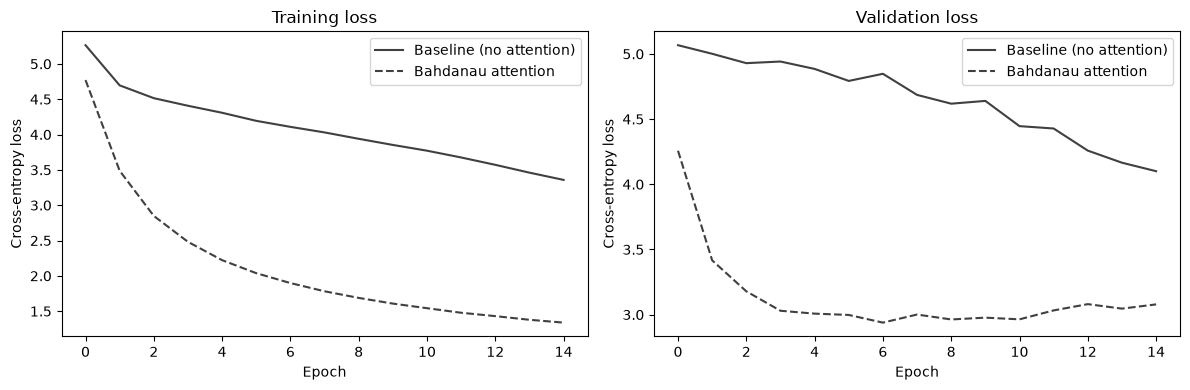

In [16]:
# [RUN] — loss curve comparison

fig_losses, axes = plt.subplots(1, 2, figsize=(12, 4))
for hist, label, style in [
    (baseline_history, 'Baseline (no attention)', '-'),
    (attn_history,     'Bahdanau attention',      '--'),
]:
    axes[0].plot(hist['train'], linestyle=style, color='#404040', label=label)
    axes[1].plot(hist['val'],   linestyle=style, color='#404040', label=label)
for ax, title in zip(axes, ['Training loss', 'Validation loss']):
    ax.set_xlabel('Epoch'); ax.set_ylabel('Cross-entropy loss')
    ax.set_title(title); ax.legend()
plt.tight_layout(); plt.show()

In [17]:
# Bottleneck comparison: loss by length for both models
attn_length_loss = loss_by_length(
    attn_model, val_pairs[:500], en_vocab, de_vocab,
    DEVICE, length_bins)

print(f"{'Length bin':<15s} {'Baseline':>10s}  {'Attention':>10s}  {'Gap':>8s}")
print("-" * 48)
for bin_label in bl_length_loss:
    bl  = bl_length_loss[bin_label]
    att = attn_length_loss.get(bin_label, float('nan'))
    print(f"{bin_label:<15s} {bl:>10.4f}  {att:>10.4f}  {bl-att:>+8.4f}")

Length bin        Baseline   Attention       Gap
------------------------------------------------
1-4                 4.4674      5.4340   -0.9666
5-7                 2.7523      1.7163   +1.0360
8-10                3.7324      2.3583   +1.3741
11-13               4.0700      2.8456   +1.2244
14-16               4.1837      3.0592   +1.1245
17-20               4.4129      3.3017   +1.1112


### 2.4 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** The length-gap table above shows how much the attention model outperforms the baseline, broken down by sentence length. Does the gap widen at longer lengths? Connect what you observe to the bottleneck mechanism from Part 1 — why should the attention advantage be larger for longer sentences?

**Question B:** Bahdanau attention uses an *additive* alignment model (a tanh non-linearity and a learned vector `v_a`). Luong (2015) proposed a simpler *multiplicative* (dot-product) alignment: $e_{ti} = s_t^\top h_i$. Identify one situation where additive attention would be expected to outperform multiplicative, and explain the architectural reason.

**Your reflection:**

**A.** No: the free-running gap is +1.0360 at 5–7 words, peaks at +1.3741 at 8–10 and narrows to +1.1112 at 17–20; only the BLEU *ratio* grows, from 0.3890/0.1684 = 2.31× to 0.2323/0.0804 = 2.89× (Part 5.2). The bottleneck predicts a widening gap because the baseline squeezes a sentence of any length into the same 256 numbers, while attention re-reads every encoder state at every step. The trend is hard to see here because sentences stop at 20 tokens (149 + 166 + 109 = 424 of the 500 sampled have 8–16 words), short of the lengths where Bahdanau et al. (2015) show the fixed-vector model degrading, and because the gap is already +1.0360 at 5–7 words, so most of the baseline's deficit is recovering exact content words from one compressed vector at any length.

**B.** Additive attention should win when decoder and encoder states differ in size, as in this model: $s_{t-1}$ is 256-d and each bidirectional $h_i$ is 512-d, so Luong's $s_t^\top h_i$ is undefined without an extra matrix, while $W_{\text{dec}}$ and $W_{\text{enc}}$ project both into a shared 256-d space (J&M, *RNNs and LSTMs*: dot-product attention needs equal dimensionality). The tanh and $v_a$ also make the score a one-hidden-layer network with a bounded range, whereas an unscaled dot product's variance grows with the dimension and saturates the softmax; Vaswani et al. (2017) find additive attention beats unscaled dot-product attention for large $d_k$, which is why they divide by $\sqrt{d_k}$.

---

## Part 3 — Attention Weight Analysis (20 points)

Attention weights are interpretable: $\alpha_{ti}$ tells you how much the decoder attended to source position $i$ when generating target position $t$. Plotting the full weight matrix as a heatmap reveals the alignment structure the model has learned.

For English→German translation, several linguistic patterns are expected:
- **Near-diagonal** alignment for content words with similar positions
- **Article shifts**: German uses grammatical gender (*der/die/das*) determined by the noun — the article position may shift relative to English *the/a*
- **Verb-final patterns**: German subordinate clauses place verbs at the end, creating off-diagonal blocks
- **Compound nouns**: German compound words may attend to multiple English tokens

### 3.1 — Translate and extract attention weights

In [18]:
def translate_with_attention(model, src_tokens, src_vocab, tgt_vocab,
                              device, max_len=50):
    """Translate a token sequence and return attention weight matrix.

    Args:
        model      (Seq2SeqAttention): Trained attention model.
        src_tokens (list[str]):        Source tokens (no special tokens).
        src_vocab  (Vocabulary):       Source vocabulary.
        tgt_vocab  (Vocabulary):       Target vocabulary.
        device     (torch.device):     Device to run the model on.
        max_len    (int):              Maximum decoding steps.

    Returns:
        tuple:
            translation (str):         Decoded output sentence.
            attention   (np.ndarray):  Shape (tgt_len, src_len+1) —
                                       rows are decoder steps, columns
                                       are source positions (including EOS).
    """
    if not isinstance(model, Seq2SeqAttention):
        raise TypeError("translate_with_attention needs a Seq2SeqAttention model")
    src = source_tensor(src_tokens, src_vocab, device)          # tokens + <EOS>
    tokens, attentions = model.translate(src, max_len=max_len)
    translation = tgt_vocab.decode(tokens)
    # translate() returns one weight vector per output word, so the rows
    # line up with translation.split().
    attention = (np.stack(attentions) if attentions
                 else np.zeros((0, src.size(1)), dtype=np.float32))
    return translation, attention


# Translate a fixed set of validation sentences
ANALYSIS_SENTENCES = [
    ('a man is riding a horse .', None),
    ('two dogs are running in the grass .', None),
    ('a woman reads a book in the park .', None),
    ('the child plays with a red ball .', None),
    ('a group of people stand near a building .', None),
]

print("Translating analysis sentences...")
for i, (en, _) in enumerate(ANALYSIS_SENTENCES):
    translation, attn = translate_with_attention(
        attn_model, en.split(), en_vocab, de_vocab, DEVICE)
    ANALYSIS_SENTENCES[i] = (en, translation, attn)
    print(f"  EN: {en}")
    print(f"  DE: {translation}")
    print()

Translating analysis sentences...
  EN: a man is riding a horse .
  DE: ein mann reitet auf einem pferd .

  EN: two dogs are running in the grass .
  DE: zwei hunde rennen im gras .

  EN: a woman reads a book in the park .
  DE: eine frau liest ein buch im park .

  EN: the child plays with a red ball .
  DE: das kind spielt mit einem roten ball .

  EN: a group of people stand near a building .
  DE: eine gruppe von menschen steht neben einem gebäude .



### 3.2 — Attention heatmap visualization

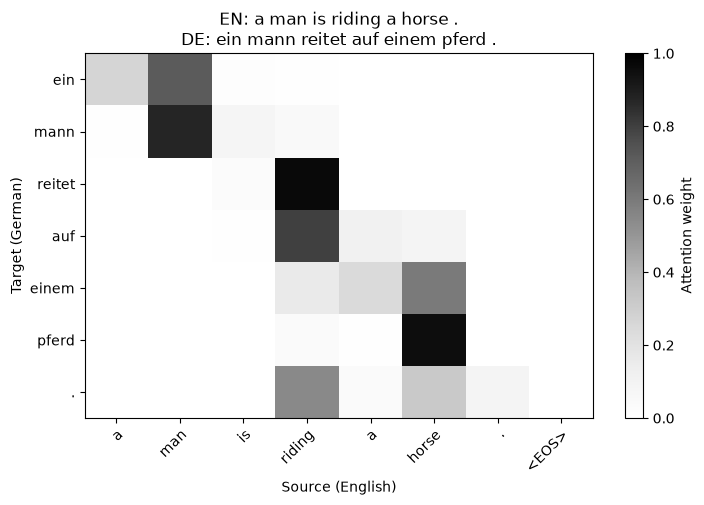

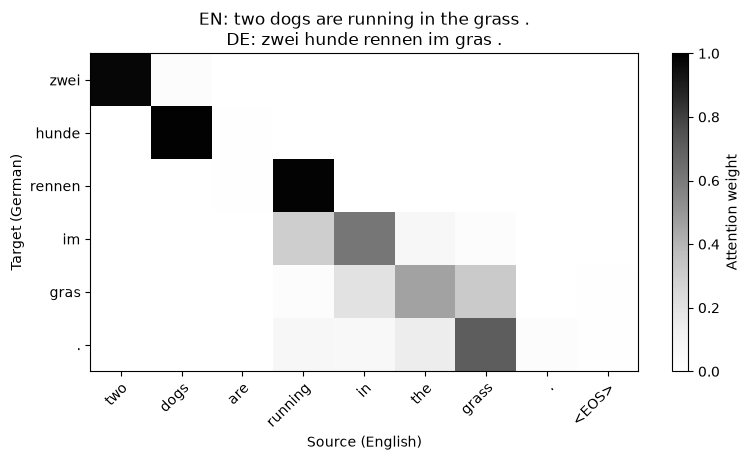

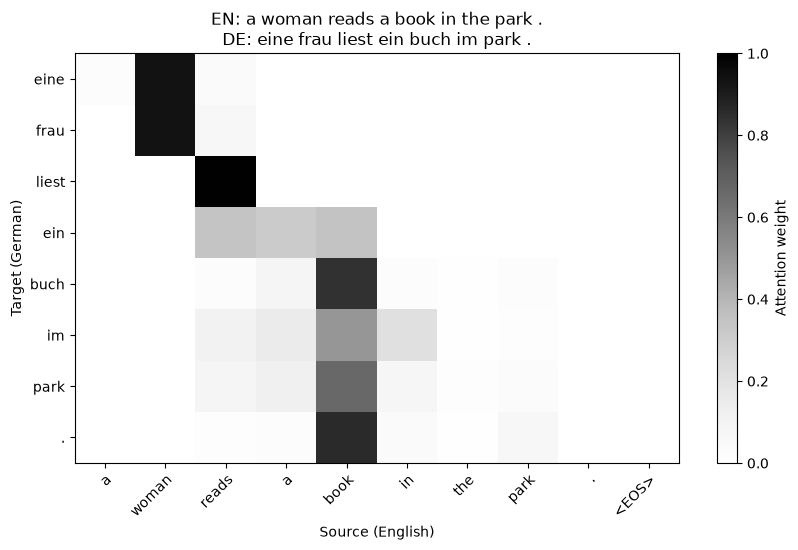

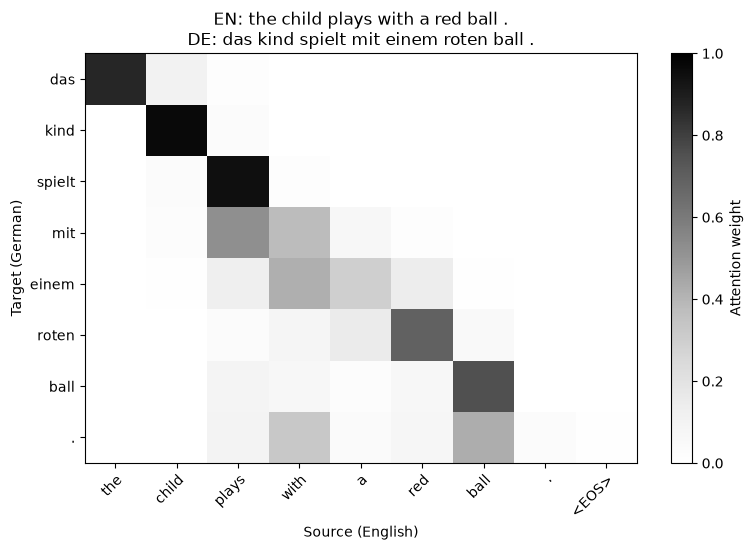

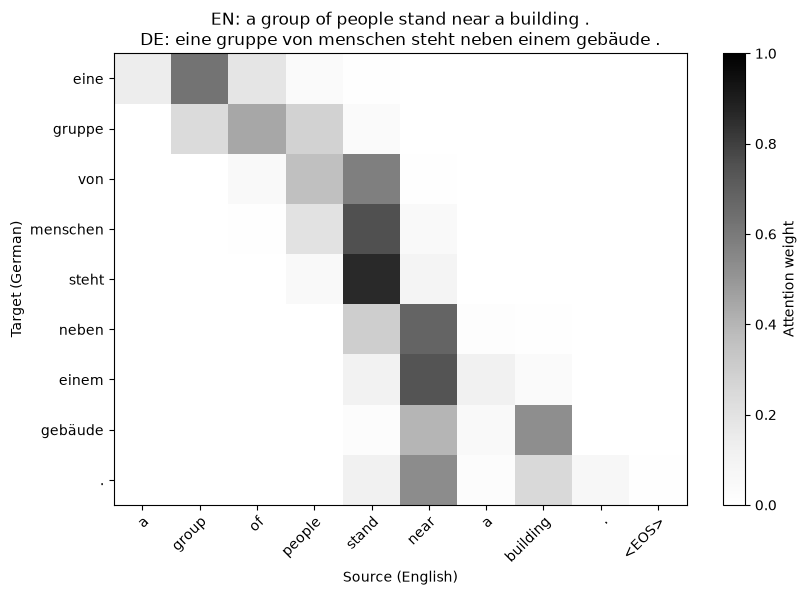

In [19]:
def plot_attention_heatmap(src_tokens, tgt_tokens, attention_matrix,
                            title=""):
    """Plot a word-level attention heatmap as a grayscale matrix.

    Rows are target (German) tokens; columns are source (English) tokens
    plus the EOS marker. Cell intensity represents attention weight.

    Args:
        src_tokens       (list[str]):   Source tokens (including <EOS>).
        tgt_tokens       (list[str]):   Target tokens (decoded output).
        attention_matrix (np.ndarray): Shape (tgt_len, src_len).
        title            (str):        Plot title.

    Returns:
        tuple: (fig, ax) matplotlib objects.
    """
    attention_matrix = np.asarray(attention_matrix)
    expected = (len(tgt_tokens), len(src_tokens))
    if attention_matrix.shape != expected or 0 in expected:
        raise ValueError(f"attention_matrix has shape {attention_matrix.shape}; the "
                         f"labels need a non-empty {expected} (target x source)")

    # Scale the figure with the sentence so every label stays readable.
    fig, ax = plt.subplots(figsize=(0.55 * len(src_tokens) + 3,
                                    0.45 * len(tgt_tokens) + 2))
    image = ax.imshow(attention_matrix, cmap='Greys', vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(len(src_tokens)))
    ax.set_xticklabels(src_tokens, rotation=45, ha='right', rotation_mode='anchor')
    ax.set_yticks(range(len(tgt_tokens)))
    ax.set_yticklabels(tgt_tokens)
    ax.set_xlabel("Source (English)")
    ax.set_ylabel("Target (German)")
    ax.set_title(title)
    fig.colorbar(image, ax=ax, label="Attention weight")
    fig.tight_layout()
    return fig, ax


for en, de, attn in ANALYSIS_SENTENCES:
    src_toks = en.split() + ['<EOS>']
    tgt_toks = de.split()
    fig_attn, _ = plot_attention_heatmap(
        src_toks, tgt_toks, attn,
        title=f"EN: {en}\nDE: {de}"
    )
    plt.show()

### 3.3 — Reflection (manually graded, 12 pts)

This reflection is worth 12 points because attention heatmap interpretation is the central analytical skill in this lab. Responses that only describe the visual pattern without connecting to linguistic mechanisms will receive partial credit.

**Prompt A (6 pts):** Choose two of the five heatmaps above. For each one, identify one specific cell or region that is *not* on the diagonal and explain the linguistic phenomenon it represents. What structural difference between English and German syntax is the model capturing at that position? Be specific: name the words involved and describe the expected German grammatical rule.

**Prompt B (6 pts):** Look across all five heatmaps and identify one systematic pattern that appears in most or all of them — something the model has learned to do consistently. Then identify one heatmap where attention is unusually diffuse (spread across many source positions) for a particular target word. Explain what that diffuse pattern might indicate: is it a limitation of the model, a property of the word, or something else?

**Your reflection:**

**A.** *Heatmap 2 (two dogs are running in the grass).* From the verb on, the alignment runs one column right of the diagonal: *rennen* (row 2) puts 0.99 on *running* (column 3), and *are* is never the top position of any row. German has no progressive aspect, so English *be* + V-*ing* becomes the single finite verb *rennen* and the auxiliary's column is skipped. *im* then contracts *in* + *dem* (dative for a location, *dem* because *Gras* is neuter), and attention lags behind this two-to-one step: *gras* (row 4) puts 0.46 on *the* and only 0.32 on *grass*.

*Heatmap 3 (a woman reads a book in the park).* Row 0, *eine*, puts 0.94 on *woman* and only 0.02 on *a*. The German indefinite article inflects for its noun's gender and case (*eine* for feminine *Frau*, *ein* for neuter *Buch*) while English *a* carries neither, so to choose the form the decoder looks one position ahead to the noun. *ein* (row 3) splits its weight over *book* (0.34), *reads* (0.34) and *a* (0.31): the noun that fixes its gender, the verb that assigns accusative case, and the article it translates.

**B.** The systematic pattern is that German articles align with the word that decides their form rather than with the English article: in 7 of the 8 article rows the top position is the noun or the case-assigning preposition (*ein*→*man* 0.71, *eine*→*woman* 0.94, *einem*→*near* 0.74), and only *das*→*the* (0.87) follows the English article. Content words meanwhile take near one-hot weights along a monotonic path: in 31 of 33 consecutive steps the top source position does not move left (Part 5.3).

In heatmap 4 (the child plays with a red ball), *einem* (row 4) is the third most diffuse of the 38 rows, 1.93 bits against 3.17 for a uniform row, spread over *with* (0.42), *a* (0.29) and *red* (0.14). I read this as a property of the word: *einem* fuses dative case from *with*, indefiniteness from *a* and the masculine gender of *red ball*, and it fixes the ending of *roten*, so it needs several source words at once. Attention is not a strict word alignment, though: in heatmap 3, *park* is produced correctly while its row puts 0.67 on *book*, most likely because the backward LSTM state at *book* has already read *in the park*, so the weights show where the decoder reads information from, not which English word it translates.

---

## Part 4 — BLEU Evaluation (16 points)

BLEU (Bilingual Evaluation Understudy, Papineni et al., 2002) is the dominant automatic metric for machine translation. It measures the geometric mean of n-gram precisions (for n=1,2,3,4), multiplied by a brevity penalty that penalises hypotheses shorter than the reference.

$$\text{BLEU} = \text{BP} \cdot \exp\!\left(\sum_{n=1}^{4} \frac{1}{4} \log p_n\right)$$

$$\text{BP} = \begin{cases} 1 & \text{if } |hyp| \geq |ref| \\ e^{1 - |ref|/|hyp|} & \text{otherwise} \end{cases}$$

where $p_n$ is **clipped** n-gram precision: the count of n-grams in the hypothesis that appear in the reference, clipped to the maximum reference count, divided by total hypothesis n-grams.

### 4.1 — Implement BLEU from scratch

In [20]:
def require_token_list(tokens, name='tokens'):
    """Raise TypeError if tokens is a string rather than a list of tokens.

    Args:
        tokens: Value to check.
        name   (str): Argument name, used in the error message.
    """
    if isinstance(tokens, str):
        raise TypeError(f"{name} must be a list of tokens, not a string; split it first")


def count_ngrams(tokens, n):
    """Count all n-gram occurrences in a token sequence.

    Args:
        tokens (list[str]): Token sequence.
        n      (int):       N-gram order.

    Returns:
        Counter: Maps n-gram tuple to frequency.
    """
    require_token_list(tokens)
    require_positive_ints(n=n)
    return Counter(tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1))


def clipped_precision(hypothesis, references, n):
    """Compute clipped n-gram precision for one sentence.

    For each n-gram in the hypothesis, its clipped count is the minimum
    of its hypothesis count and the maximum count across all references.

    Args:
        hypothesis (list[str]):        Hypothesis tokens.
        references (list[list[str]]): List of reference token lists.
        n          (int):              N-gram order.

    Returns:
        tuple[int, int]: (clipped_count, total_hypothesis_ngrams)
    """
    if not references:
        raise ValueError("at least one reference is required")
    for ref in references:
        require_token_list(ref, 'each reference')
    hyp_counts = count_ngrams(hypothesis, n)
    max_ref_counts = Counter()
    for ref in references:
        max_ref_counts |= count_ngrams(ref, n)     # | keeps the larger count
    clipped = hyp_counts & max_ref_counts          # & keeps the smaller count
    return sum(clipped.values()), sum(hyp_counts.values())


def brevity_penalty(hypothesis_len, reference_len):
    """Compute BLEU brevity penalty.

    Args:
        hypothesis_len (int): Number of tokens in hypothesis.
        reference_len  (int): Number of tokens in the closest reference.

    Returns:
        float: Brevity penalty in (0, 1].
        An empty hypothesis that is shorter than the reference scores 0.0.
    """
    if hypothesis_len < 0 or reference_len < 0:
        raise ValueError("lengths must be non-negative")
    if hypothesis_len >= reference_len:
        return 1.0
    if hypothesis_len == 0:
        return 0.0
    return math.exp(1 - reference_len / hypothesis_len)


def closest_reference_length(hypothesis_len, references):
    """Length of the reference closest in length to the hypothesis.

    Ties go to the shorter reference, as in Papineni et al. (2002) and sacrebleu.

    Args:
        hypothesis_len (int):             Hypothesis length in tokens.
        references     (list[list[str]]): Reference token lists.

    Returns:
        int
    """
    return min((len(ref) for ref in references),
               key=lambda ref_len: (abs(ref_len - hypothesis_len), ref_len))


def bleu_statistics(hypotheses, references_list, max_n=4):
    """Corpus totals that BLEU is computed from.

    Args:
        hypotheses      (list[list[str]]):        Hypothesis token lists.
        references_list (list[list[list[str]]]): For each sentence, a list
                                                  of reference token lists.
        max_n           (int):                    Maximum n-gram order.

    Returns:
        tuple:
            clipped (list[int]): Clipped n-gram matches for n = 1..max_n.
            totals  (list[int]): Hypothesis n-grams for n = 1..max_n.
            hyp_len (int):       Total hypothesis length.
            ref_len (int):       Total closest-reference length.
    """
    require_positive_ints(max_n=max_n)
    if len(hypotheses) != len(references_list):
        raise ValueError(f"{len(hypotheses)} hypotheses but "
                         f"{len(references_list)} reference sets")
    clipped, totals = [0] * max_n, [0] * max_n
    hyp_len = ref_len = 0
    for hypothesis, references in zip(hypotheses, references_list):
        for n in range(1, max_n + 1):
            c, t = clipped_precision(hypothesis, references, n)
            clipped[n - 1] += c
            totals[n - 1] += t
        hyp_len += len(hypothesis)
        ref_len += closest_reference_length(len(hypothesis), references)
    return clipped, totals, hyp_len, ref_len


def corpus_bleu_scratch(hypotheses, references_list, max_n=4):
    """Compute corpus-level BLEU score from scratch.

    Accumulates clipped n-gram counts and lengths across all sentences,
    then computes the geometric mean of clipped precisions weighted by
    the corpus-level brevity penalty.

    Args:
        hypotheses      (list[list[str]]):        Hypothesis token lists.
        references_list (list[list[list[str]]]): For each sentence, a list
                                                  of reference token lists.
        max_n           (int):                    Maximum n-gram order.

    Returns:
        float: Corpus BLEU score in [0, 1].
        No smoothing: if any order has zero clipped matches the score is 0.0.
    """
    if not hypotheses:
        raise ValueError("no sentences to score")
    clipped, totals, hyp_len, ref_len = bleu_statistics(
        hypotheses, references_list, max_n)
    if min(clipped) == 0:                      # log 0: the geometric mean is 0
        return 0.0
    mean_log_precision = sum(math.log(c / t) for c, t in zip(clipped, totals)) / max_n
    return brevity_penalty(hyp_len, ref_len) * math.exp(mean_log_precision)


# Quick verification — do not modify
assert abs(corpus_bleu_scratch(
    [['the','dog','sat','on','the','mat']],
    [[['the','dog','sat','on','the','mat']]]) - 1.0) < 1e-5, \
    "Perfect match should return 1.0"

c, t = clipped_precision(['the','the','the'], [['the','cat','sat']], 1)
assert c == 1 and t == 3, f"Clipped: expected (1,3), got ({c},{t})"

assert abs(brevity_penalty(5, 10) - math.exp(-1)) < 1e-9
assert brevity_penalty(10, 5) == 1.0
assert brevity_penalty(0, 5)  == 0.0

print("BLEU implementation: all assertions passed.")

BLEU implementation: all assertions passed.


### 4.2 — Evaluate both models with BLEU

In [21]:
def compute_corpus_bleu(model, pairs, src_vocab, tgt_vocab,
                         device, max_len=50):
    """Compute corpus BLEU for a model on a set of sentence pairs.

    Args:
        model     (nn.Module):       Trained seq2seq model.
        pairs     (list[tuple]):     (src_tokens, tgt_tokens) pairs.
        src_vocab (Vocabulary):      Source vocabulary.
        tgt_vocab (Vocabulary):      Target vocabulary.
        device    (torch.device):    Device to run the model on.
        max_len   (int):             Maximum decoding length.

    Returns:
        tuple:
            bleu_score   (float):               Corpus BLEU.
            translations (list[tuple[str,str]]): (reference, hypothesis) pairs.
    """
    if not pairs:
        raise ValueError("pairs is empty")
    translations = []
    for src_tokens, tgt_tokens in pairs:
        output = model.translate(source_tensor(src_tokens, src_vocab, device),
                                 max_len=max_len)
        # Seq2SeqAttention.translate also returns the attention weights.
        tokens = output[0] if isinstance(model, Seq2SeqAttention) else output
        # The reference is the full normalised sentence, including words
        # outside the vocabulary that the model can never produce.
        translations.append((' '.join(tgt_tokens), tgt_vocab.decode(tokens)))
    bleu_score = corpus_bleu_scratch([hyp.split() for _, hyp in translations],
                                     [[ref.split()] for ref, _ in translations])
    return bleu_score, translations


print("Computing BLEU (baseline)...")
bl_bleu, bl_translations = compute_corpus_bleu(
    baseline_model, val_pairs, en_vocab, de_vocab, DEVICE)

print("Computing BLEU (attention)...")
at_bleu, at_translations = compute_corpus_bleu(
    attn_model, val_pairs, en_vocab, de_vocab, DEVICE)

# Named output variables
baseline_bleu = bl_bleu
attention_bleu = at_bleu

print(f"\n{'Model':<25s} {'Corpus BLEU':>12s}")
print("-" * 40)
print(f"{'Baseline (no attention)':<25s} {baseline_bleu:>12.4f}")
print(f"{'Bahdanau attention':<25s} {attention_bleu:>12.4f}")

Computing BLEU (baseline)...


Computing BLEU (attention)...



Model                      Corpus BLEU
----------------------------------------
Baseline (no attention)         0.0979
Bahdanau attention              0.2836


In [22]:
# [RUN] — best and worst BLEU sentences (attention model)

scored = sorted(enumerate(at_translations),
                key=lambda x: corpus_bleu_scratch(
                    [x[1][1].split()], [[x[1][0].split()]]))

print("=== Five highest BLEU (attention model) ===")
for _, (ref, hyp) in scored[-5:][::-1]:
    s = corpus_bleu_scratch([hyp.split()], [[ref.split()]])
    print(f"  BLEU={s:.3f}  ref='{ref}'  hyp='{hyp}'")

print("\n=== Five lowest BLEU (attention model) ===")
for _, (ref, hyp) in scored[:5]:
    s = corpus_bleu_scratch([hyp.split()], [[ref.split()]])
    print(f"  BLEU={s:.3f}  ref='{ref}'  hyp='{hyp}'"  )

=== Five highest BLEU (attention model) ===
  BLEU=1.000  ref='drei hunde spielen im wasser .'  hyp='drei hunde spielen im wasser .'
  BLEU=1.000  ref='eine frau steht vor bäumen und lächelt .'  hyp='eine frau steht vor bäumen und lächelt .'
  BLEU=1.000  ref='ein tänzer in einem roten anzug springt in die luft .'  hyp='ein tänzer in einem roten anzug springt in die luft .'
  BLEU=1.000  ref='zwei männer in shorts arbeiten an einem blauen fahrrad .'  hyp='zwei männer in shorts arbeiten an einem blauen fahrrad .'
  BLEU=1.000  ref='eine familie steht an einem bewölkten tag im freien .'  hyp='eine familie steht an einem bewölkten tag im freien .'

=== Five lowest BLEU (attention model) ===
  BLEU=0.000  ref='eine gruppe von männern lädt baumwolle auf einen lastwagen'  hyp='eine gruppe von lädt auf einen lkw .'
  BLEU=0.000  ref='ein junge mit kopfhörern sitzt auf den schultern einer frau .'  hyp='ein junge mit kopfhörer sitzt auf einem schultern .'
  BLEU=0.000  ref='zwei männer bauen ei

### 4.3 — Compare with sacrebleu

In [23]:
import sacrebleu

# sacrebleu expects a list of hypotheses and a list-of-lists of references
sacre_refs  = [[ref for ref, _   in at_translations]]
sacre_hyps  =  [hyp for _,   hyp in at_translations]

sacrebleu_score = sacrebleu.corpus_bleu(sacre_hyps, sacre_refs).score / 100
print(f"Our BLEU implementation: {attention_bleu:.4f}")
print(f"sacrebleu corpus BLEU:   {sacrebleu_score:.4f}")
print(f"Difference:              {abs(attention_bleu - sacrebleu_score):.4f}")
print()
print("Small differences are expected: sacrebleu uses a different tokenisation")
print("and smoothing strategy. Large differences indicate a bug in your implementation.")

That's 100 lines that end in a tokenized period ('.')


It looks like you forgot to detokenize your test data, which may hurt your score.


If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


Our BLEU implementation: 0.2836
sacrebleu corpus BLEU:   0.2836
Difference:              0.0000

Small differences are expected: sacrebleu uses a different tokenisation
and smoothing strategy. Large differences indicate a bug in your implementation.


### 4.4 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** From the lowest-BLEU outputs, find one case where the BLEU score is low but the translation is semantically correct or reasonable. Explain specifically which property of BLEU causes the low score for that example — is it n-gram order sensitivity, the brevity penalty, lack of synonym handling, or something else?

**Question B:** BLEU correlates well with human judgments at the corpus level but poorly at the sentence level, and it has well-known failure modes. Describe one translation error type that BLEU *cannot* detect and explain why the metric is blind to it. Then propose one concrete evaluation approach that would catch that error type.

**Your reflection:**

**A.** Sentence 56 (*three women smiling and sitting down .*) becomes *drei frauen lächeln und sitzen .*, an accurate translation, yet one of the 499 translations tied at the lowest sentence BLEU, 0.000 (Part 5.4): all 6 of its words occur in the reference *drei frauen sitzen da und lächeln .* (p1 = 6/6), but because the reference orders the verbs the other way and adds *da*, only 1 of 5 bigrams and no trigram or 4-gram match. The cause is n-gram order sensitivity combined with BLEU's unsmoothed geometric mean: one zero precision (p3 = 0/4, p4 = 0/3) zeroes the whole score, so a legitimate reordering of conjuncts scores the same as gibberish, with the brevity penalty (0.846) only a minor second factor.

**B.** BLEU cannot tell a meaning-reversing error from a harmless wording change, because it counts surface n-gram matches and every unmatched token costs the same: inserting *nicht* into a reference scores exactly the same 0.7349 as inserting the harmless *gerade*, and replacing *mann* with *hund* in 244 references still scores corpus BLEU 0.8206, 0.8206 / 0.2836 = 2.89 times our attention model (Part 5.5). A contrastive minimal-pair test (Sennrich, 2017) catches this by asking the model to score the correct translation against a minimally corrupted one: the attention model prefers the original in 243 of 244 *mann*→*hund* pairs and all 49 *hund*→*mann* pairs. For system outputs, the matching tools are human error annotation or a learned metric such as COMET (J&M, *Machine Translation*).

---

## Part 5 — Supporting checks (ungraded)

These cells run after every graded cell and only read the graded variables and trained models, so no graded value changes. They print the exact numbers the reflections quote.

### 5.1 — Vocabulary coverage, bin sizes, and what each decoder can see (Parts 1–2)

In [24]:
def unknown_rate(pairs, vocab, side):
    """Share of tokens on one side of the pairs that the vocabulary maps to <UNK>.

    Args:
        pairs (list[tuple]): (src_tokens, tgt_tokens) pairs.
        vocab (Vocabulary):  Vocabulary for that side.
        side  (int):         0 for source, 1 for target.

    Returns:
        float: Fraction of tokens not in vocab.w2i.
    """
    tokens = [tok for pair in pairs for tok in pair[side]]
    return sum(tok not in vocab.w2i for tok in tokens) / len(tokens)


print(f"Unknown-token rate on validation: English {unknown_rate(val_pairs, en_vocab, 0):.4f}, "
      f"German {unknown_rate(val_pairs, de_vocab, 1):.4f}")

bin_labels = length_bin_labels(length_bins)
sample_bins = Counter(bin_labels[length_bin_index(len(en), length_bins)]
                      for en, _ in val_pairs[:500])
print("\nSentences per source-length bin in val_pairs[:500] (the loss-by-length sample):")
for label in bin_labels:
    print(f"  {label:<6s} {sample_bins[label]:>4d}")

max_positions = length_bins[-1] + 1                     # 20 words + <EOS>
print(f"\nDecoder state: {HIDDEN_DIM}-d.  Encoder states: {ENC_DIM}-d per source position.")
print(f"For a {length_bins[-1]}-word source, the attention decoder can read "
      f"{max_positions} x {ENC_DIM} = {max_positions * ENC_DIM:,} encoder values at every step;")
print(f"the baseline decoder sees one {HIDDEN_DIM}-d summary vector for any sentence length.")
n_attention = count_params(attn_model.decoder.attention)
print(f"Alignment-model parameters (W_dec, W_enc, v_a): {n_attention:,}")

Unknown-token rate on validation: English 0.0212, German 0.0446

Sentences per source-length bin in val_pairs[:500] (the loss-by-length sample):
  1-4       1
  5-7      17
  8-10    149
  11-13   166
  14-16   109
  17-20    58

Decoder state: 256-d.  Encoder states: 512-d per source position.
For a 20-word source, the attention decoder can read 21 x 512 = 10,752 encoder values at every step;
the baseline decoder sees one 256-d summary vector for any sentence length.
Alignment-model parameters (W_dec, W_enc, v_a): 196,864


### 5.2 — Length effects with the gold prefix, and BLEU by length (Parts 1–2)

The graded loss-by-length tables decode free-running, so a long sentence's loss also includes errors that compound after the first wrong word. Feeding the gold prefix (`teacher_forcing_ratio=1.0`) removes that compounding and leaves how well each decoder can draw on the source. The BLEU table uses the full validation set; *len ratio* is total hypothesis length over total reference length.

In [25]:
def bleu_by_length(translations, pairs, length_bins):
    """Corpus BLEU and length ratio of translations grouped by source-length bin.

    Args:
        translations (list[tuple[str, str]]): (reference, hypothesis) pairs,
                                              aligned with pairs.
        pairs        (list[tuple]):           (src_tokens, tgt_tokens) pairs.
        length_bins  (list[int]):             Bin boundaries.

    Returns:
        dict[str, tuple[float, float, int]]: bin label -> (BLEU, len ratio, n).
    """
    if len(translations) != len(pairs):
        raise ValueError("translations and pairs must be aligned")
    labels = length_bin_labels(length_bins)
    groups = defaultdict(list)
    for (ref, hyp), (src_tokens, _) in zip(translations, pairs):
        b = length_bin_index(len(src_tokens), length_bins)
        if b is not None:
            groups[labels[b]].append((ref.split(), hyp.split()))
    results = {}
    for label in labels:
        if groups[label]:
            refs = [[ref] for ref, _ in groups[label]]
            hyps = [hyp for _, hyp in groups[label]]
            _, _, hyp_len, ref_len = bleu_statistics(hyps, refs)
            results[label] = (corpus_bleu_scratch(hyps, refs), hyp_len / ref_len,
                              len(hyps))
    return results


bl_tf_loss = loss_by_length(baseline_model, val_pairs[:500], en_vocab, de_vocab,
                            DEVICE, length_bins, teacher_forcing_ratio=1.0)
at_tf_loss = loss_by_length(attn_model, val_pairs[:500], en_vocab, de_vocab,
                            DEVICE, length_bins, teacher_forcing_ratio=1.0)
print("Loss by source length with the gold prefix (val_pairs[:500]):")
print(f"{'Length bin':<12s} {'Baseline':>9s} {'Attention':>10s} {'Gap':>8s}")
for label in bl_tf_loss:
    gap = bl_tf_loss[label] - at_tf_loss[label]
    print(f"{label:<12s} {bl_tf_loss[label]:>9.4f} {at_tf_loss[label]:>10.4f} {gap:>+8.4f}")

bl_by_len = bleu_by_length(bl_translations, val_pairs, length_bins)
at_by_len = bleu_by_length(at_translations, val_pairs, length_bins)
print("\nCorpus BLEU by source length (full validation set):")
print(f"{'Length bin':<12s} {'n':>4s} {'BLEU base':>10s} {'BLEU attn':>10s} {'Gap':>8s} "
      f"{'len ratio base':>15s} {'len ratio attn':>15s}")
for label, (bl_score, bl_ratio, n) in bl_by_len.items():
    at_score, at_ratio, _ = at_by_len[label]
    print(f"{label:<12s} {n:>4d} {bl_score:>10.4f} {at_score:>10.4f} "
          f"{at_score - bl_score:>+8.4f} {bl_ratio:>15.3f} {at_ratio:>15.3f}")

Loss by source length with the gold prefix (val_pairs[:500]):
Length bin    Baseline  Attention      Gap
1-4             4.1228     5.1518  -1.0290
5-7             1.9483     1.1219  +0.8265
8-10            2.6910     1.5744  +1.1166
11-13           2.8582     1.8479  +1.0103
14-16           2.9568     1.9604  +0.9964
17-20           3.1449     2.1826  +0.9624

Corpus BLEU by source length (full validation set):
Length bin      n  BLEU base  BLEU attn      Gap  len ratio base  len ratio attn
1-4             1     0.0000     0.0000  +0.0000           2.000           2.000
5-7            28     0.1684     0.3890  +0.2206           0.904           0.957
8-10          253     0.1171     0.3293  +0.2122           0.824           0.936
11-13         324     0.0931     0.2833  +0.1902           0.813           0.899
14-16         224     0.0981     0.2806  +0.1825           0.829           0.888
17-20         121     0.0804     0.2323  +0.1519           0.832           0.893


### 5.3 — The attention heatmaps in numbers (Part 3)

For every German output word: the three source positions with the most weight (`word[position]` and weight) and the row's entropy in bits. A row spread evenly over *n* positions has entropy log2(*n*); a row on a single position has 0.

In [26]:
def row_entropy_bits(weights):
    """Entropy in bits of one attention row.

    Args:
        weights (array-like): Attention weights over source positions, summing to 1.

    Returns:
        float: 0 for a one-hot row, log2(n) for a uniform row over n positions.
    """
    weights = np.asarray(weights, dtype=np.float64)
    nonzero = weights[weights > 0]
    return float(-(nonzero * np.log2(nonzero)).sum())


def describe_alignment(en, de, attn, top_k=3):
    """Print the top-k source positions and the entropy of each attention row.

    Args:
        en   (str):        Source sentence.
        de   (str):        Model translation.
        attn (np.ndarray): Shape (len(de.split()), len(en.split()) + 1).
        top_k (int):       Number of source positions to list per row.
    """
    src = en.split() + ['<EOS>']
    print(f"EN: {en}\nDE: {de}   (uniform row: {math.log2(len(src)):.2f} bits)")
    for t, (word, weights) in enumerate(zip(de.split(), attn)):
        top = np.argsort(weights)[::-1][:top_k]
        cells = "  ".join(f"{src[i] + f'[{i}]':<12s} {weights[i]:.2f}" for i in top)
        print(f"  {t:>2d} {word:<14s} {cells}   H={row_entropy_bits(weights):.2f}")
    print()


for en, de, attn in ANALYSIS_SENTENCES:
    describe_alignment(en, de, attn)

top_weights = np.concatenate([attn.max(axis=1) for _, _, attn in ANALYSIS_SENTENCES])
print(f"Rows: {len(top_weights)}.  Top weight >= 0.5 in {(top_weights >= 0.5).sum()} rows; "
      f"mean top weight {top_weights.mean():.3f}.")
steps = np.concatenate([np.diff(attn.argmax(axis=1)) for _, _, attn in ANALYSIS_SENTENCES])
print(f"Consecutive output words whose top source position does not move left: "
      f"{(steps >= 0).sum()} of {len(steps)}.")

EN: a man is riding a horse .
DE: ein mann reitet auf einem pferd .   (uniform row: 3.00 bits)
   0 ein            man[1]       0.71  a[0]         0.27  is[2]        0.01   H=1.01
   1 mann           man[1]       0.87  is[2]        0.08  riding[3]    0.04   H=0.71
   2 reitet         riding[3]    0.97  is[2]        0.03  man[1]       0.00   H=0.23
   3 auf            riding[3]    0.80  a[4]         0.11  horse[5]     0.09   H=0.97
   4 einem          horse[5]     0.60  a[4]         0.24  riding[3]    0.15   H=1.38
   5 pferd          horse[5]     0.95  riding[3]    0.04  a[4]         0.01   H=0.33
   6 .              riding[3]    0.54  horse[5]     0.32  .[6]         0.09   H=1.55

EN: two dogs are running in the grass .
DE: zwei hunde rennen im gras .   (uniform row: 3.17 bits)
   0 zwei           two[0]       0.97  dogs[1]      0.02  are[2]       0.00   H=0.20
   1 hunde          dogs[1]      0.99  are[2]       0.01  two[0]       0.00   H=0.09
   2 rennen         running[3]   0.99  a

### 5.4 — BLEU cross-check and sentence-level breakdown (Part 4, Question A)

With sacrebleu's own tokeniser and smoothing switched off, it scores exactly what `corpus_bleu_scratch` scores, so the gap in 4.3 comes from those two settings. The tables then break sentence-level BLEU into its parts: clipped matches over hypothesis n-grams for n = 1..4 and the brevity penalty.

In [27]:
raw_sacrebleu = sacrebleu.corpus_bleu(sacre_hyps, sacre_refs, tokenize='none',
                                      smooth_method='none').score / 100
print(f"Ours: {attention_bleu:.6f}   sacrebleu (tokenize='none', no smoothing): "
      f"{raw_sacrebleu:.6f}   difference {abs(attention_bleu - raw_sacrebleu):.2e}")


def sentence_breakdown(ref, hyp):
    """Clipped n-gram counts, brevity penalty and BLEU for one sentence.

    Args:
        ref (str): Reference sentence.
        hyp (str): Hypothesis sentence.

    Returns:
        tuple: (clipped list, totals list, brevity penalty, BLEU)
    """
    clipped, totals, hyp_len, ref_len = bleu_statistics([hyp.split()], [[ref.split()]])
    return (clipped, totals, brevity_penalty(hyp_len, ref_len),
            corpus_bleu_scratch([hyp.split()], [[ref.split()]]))


def print_breakdown(index, ref, hyp):
    """Print source, reference, hypothesis and the BLEU parts of one sentence.

    Args:
        index (int): Position in val_pairs, used to print the English source.
        ref   (str): Reference sentence.
        hyp   (str): Hypothesis sentence.
    """
    clipped, totals, bp, score = sentence_breakdown(ref, hyp)
    precisions = "  ".join(f"p{n}={c}/{t}" for n, (c, t) in enumerate(zip(clipped, totals), 1))
    print(f"  [{index}] EN:  {' '.join(val_pairs[index][0])}")
    print(f"        ref: {ref}\n        hyp: {hyp}")
    print(f"        {precisions}  BP={bp:.3f}  BLEU={score:.3f}")


breakdowns = [sentence_breakdown(ref, hyp) for ref, hyp in at_translations]
zero_idx = [i for i, b in enumerate(breakdowns) if b[3] == 0.0]
no_4gram = sum(breakdowns[i][0][3] == 0 for i in zero_idx)
print(f"\nAttention translations with sentence BLEU 0: {len(zero_idx)} of {len(at_translations)}; "
      f"{no_4gram} of them have no matching 4-gram.")

print("\nThe five lowest-BLEU sentences from 4.2:")
for index, (ref, hyp) in scored[:5]:
    print_breakdown(index, ref, hyp)

# Zero-BLEU sentences that still match most of their words.
by_unigram = sorted(zero_idx, key=lambda i: -breakdowns[i][0][0] / max(breakdowns[i][1][0], 1))
print("\nSentence-BLEU-0 translations with the highest unigram precision:")
for index in by_unigram[:6]:
    print_breakdown(index, *at_translations[index])

That's 100 lines that end in a tokenized period ('.')


It looks like you forgot to detokenize your test data, which may hurt your score.


If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


Ours: 0.283627   sacrebleu (tokenize='none', no smoothing): 0.283627   difference 5.55e-17



Attention translations with sentence BLEU 0: 499 of 951; 499 of them have no matching 4-gram.

The five lowest-BLEU sentences from 4.2:
  [0] EN:  a group of men are loading cotton onto a truck
        ref: eine gruppe von männern lädt baumwolle auf einen lastwagen
        hyp: eine gruppe von lädt auf einen lkw .
        p1=6/8  p2=3/7  p3=1/6  p4=0/5  BP=0.882  BLEU=0.000
  [2] EN:  a boy wearing headphones sits on a woman's shoulders .
        ref: ein junge mit kopfhörern sitzt auf den schultern einer frau .
        hyp: ein junge mit kopfhörer sitzt auf einem schultern .
        p1=7/9  p2=3/8  p3=1/7  p4=0/6  BP=0.801  BLEU=0.000
  [3] EN:  two men setting up a blue ice fishing hut on an iced over lake
        ref: zwei männer bauen eine blaue eisfischerhütte auf einem zugefrorenen see auf
        hyp: zwei männer richten auf einem blauen auf auf einer über eine .
        p1=6/12  p2=2/11  p3=0/10  p4=0/9  BP=1.000  BLEU=0.000
  [6] EN:  a young boy wearing a giants jersey swing

### 5.5 — A meaning error BLEU barely sees, and a contrastive check that does (Part 4, Question B)

First, one validation reference with a negation inserted after its verb, against the same reference with a harmless adverb (*gerade*, "right now") in the same slot. Second, every validation reference containing *mann* whose English source does not mention a dog gets *mann* replaced by *hund*, a fluent sentence with the wrong subject (both nouns are masculine, so articles still agree). BLEU scores each corrupted reference against the original. The contrastive check asks the model which version it finds more probable given the English source. The swap also runs the other way (*hund* → *mann* where the source mentions no man), so a model that simply preferred the more frequent word could not pass both directions.

In [28]:
MAIN_VERBS = {'sitzt', 'steht', 'fährt', 'spielt', 'läuft', 'arbeitet', 'trägt',
              'hält', 'geht', 'springt', 'schläft', 'liegt', 'schaut', 'macht'}
# First validation reference of the form "ein mann <verb> ...".
neg_ref = next(de for _, de in val_pairs if de[:2] == ['ein', 'mann'] and de[2] in MAIN_VERBS)
negated = neg_ref[:3] + ['nicht'] + neg_ref[3:]
harmless = neg_ref[:3] + ['gerade'] + neg_ref[3:]
print(f"reference: {' '.join(neg_ref)}")
for label, hyp in [("negated", negated), ("harmless", harmless)]:
    print(f"  {label:<9s} BLEU={corpus_bleu_scratch([hyp], [[neg_ref]]):.4f}  {' '.join(hyp)}")


def sequence_log_prob(model, src_tokens, tgt_tokens):
    """Log-probability the model gives a target sentence (plus <EOS>) for a source.

    Args:
        model      (nn.Module): Trained seq2seq model.
        src_tokens (list[str]): Source tokens.
        tgt_tokens (list[str]): Target tokens.

    Returns:
        float: Sum of per-token log-probabilities under the gold prefix.
    """
    src = source_tensor(src_tokens, en_vocab, DEVICE)
    tgt = torch.tensor([de_vocab.encode(tgt_tokens)], dtype=torch.long, device=DEVICE)
    was_training = model.training
    model.eval()
    with torch.no_grad():
        log_probs = F.log_softmax(model(src, tgt, teacher_forcing_ratio=1.0)[0, 1:], dim=-1)
    model.train(was_training)
    return float(log_probs.gather(1, tgt[0, 1:].unsqueeze(1)).sum())


def swapped_references(old, new, exclude):
    """Validation pairs with one reference word swapped for another.

    Args:
        old     (str):      Word to replace in the German reference.
        new     (str):      Replacement word.
        exclude (set[str]): Skip pairs whose English source contains any of these.

    Returns:
        list[tuple]: (source tokens, reference tokens, corrupted reference tokens).
    """
    return [(en, de, [new if tok == old else tok for tok in de])
            for en, de in val_pairs if old in de and not exclude & set(en)]


for old, new, exclude in [('mann', 'hund', {'dog', 'dogs'}),
                          ('hund', 'mann', {'man', 'men'})]:
    swaps = swapped_references(old, new, exclude)
    swap_bleu = corpus_bleu_scratch([bad for _, _, bad in swaps],
                                    [[de] for _, de, _ in swaps])
    print(f"\n{len(swaps)} references with '{old}' -> '{new}': corpus BLEU of the "
          f"corrupted references against the originals = {swap_bleu:.4f}")
    for label, model in [("Baseline", baseline_model), ("Attention", attn_model)]:
        prefers = [sequence_log_prob(model, en, de) > sequence_log_prob(model, en, bad)
                   for en, de, bad in swaps]
        print(f"  {label:<9s} prefers the original in {sum(prefers)} of {len(prefers)} "
              f"({np.mean(prefers):.4f})")

reference: ein mann schläft in einem grünen raum auf einem sofa .
  negated   BLEU=0.7349  ein mann schläft nicht in einem grünen raum auf einem sofa .
  harmless  BLEU=0.7349  ein mann schläft gerade in einem grünen raum auf einem sofa .

244 references with 'mann' -> 'hund': corpus BLEU of the corrupted references against the originals = 0.8206


  Baseline  prefers the original in 243 of 244 (0.9959)


  Attention prefers the original in 243 of 244 (0.9959)

49 references with 'hund' -> 'mann': corpus BLEU of the corrupted references against the originals = 0.7584


  Baseline  prefers the original in 45 of 49 (0.9184)


  Attention prefers the original in 49 of 49 (1.0000)


---

## Submission checklist

Before uploading to Canvas:

- [x] All cells run top-to-bottom without errors (**Runtime → Run all**)
- [x] All four reflections filled in
- [x] Named output variables defined:  
  `baseline_history`, `attn_history`,  
  `bl_length_loss`, `attn_length_loss`,  
  `baseline_bleu`, `attention_bleu`,  
  `bl_translations`, `at_translations`
- [x] `ANALYSIS_SENTENCES` contains five completed (en, de, attn) tuples
- [x] All five attention heatmaps rendered
- [x] Every function has a complete docstring
- [x] File saved as `Lab_8.ipynb`